# Лабораторна робота №3
# Думич Софія ОІ-35

**Тема:** Тренування, оцінювання та оптимізація моделі машинного навчання  
**Мета:** Підібрати відповідну модель для бізнес-проблеми, налаштувати її тренування, обрати метрики, оптимізувати гіперпараметри та оцінити важливість ознак, використовуючи реальні дані з бази підприємства.  
**Клієнт:** AstroVision Observatory  
### Варіант 1 (8 порядковий у журналі)

**Star Classification Dataset - Stellar Properties**

**Опис Компанії-Замовника:** AstroVision Observatory — наукова організація, яка займається автоматизованим аналізом астрономічних спостережень і формуванням каталогів небесних об’єктів.

**Запит:** Обсерваторія отримує велику кількість записів про фізичні характеристики зір. Ручне визначення типу кожного об’єкта потребує значного часу, тому необхідно автоматизувати первинну класифікацію зір.

**Пропозиція Реалізації:** Розробити модель багатокласової класифікації, яка визначатиме тип зорі (`Star_Type`) на основі температури, світності, радіуса, маси, зоряної величини, спектрального класу, кольору та інших характеристик. Модель класифікуватиме об’єкти як коричневі карлики, червоні карлики, зорі головної послідовності, білі карлики, гіганти, надгіганти або гіпергіганти.

## 1. Вибір техніки моделювання, модельні припущення та метрики (Пункти 1, 2, 3)

### 1.1. Обґрунтування техніки моделювання 

- **Стиль навчання:** Оскільки в базі даних astro_vision.db наявна розмічена історична вибірка (10 000 записів) з відомою цільовою змінною Star_Type, використовується навчання з вчителем (Supervised Learning)
- **Тип задачі:** Цільова змінна Star_Type є дискретною категоріальною ознакою, яка приймає 7 наперед відомих класів (0..6). Отже, бізнес-проблема вирішується методами багатокласової класифікації (Multiclass Classification). Регресія не підходить, бо коди класів є номінальними мітками, а не неперервними числами; кластеризація не потрібна, оскільки класи вже визначені астрофізичним каталогом.
- **Обрані моделі для порівняння:**
  1. LogisticRegression — базова лінійна модель (baseline).
  2. DecisionTreeClassifier — нелінійне дерево рішень, що будує ієрархічні порогові правила.
  3. RandomForestClassifier — беггінг-ансамбль незалежних дерев рішень, стійкий до перенавчання та шуму.
  4. GradientBoostingClassifier — бустинг-ансамбль, що послідовно мінімізує помилки попередніх дерев.

### 1.2. Модельні припущення та їх виконання у наших даних 
1. **Відсутність пропущених значень (NaN) та числовий тип усіх ознак:** обов'язкова вимога для всіх алгоритмів scikit-learn. 
**Виконується після синхронізації** таблиці stars_data_cleaned з пайплайном ЛР №2 (пропуски заповнено медіаною/модою, категорії закодовано через LabelEncoder): після запису в SQLite у цій таблиці виявились пропуски, тому дані відновлено.
2. **Масштабування ознак та лінійна роздільність класів (LogisticRegression):** лінійна модель припускає лінійну залежність між ознаками і логарифмом шансів класів, відсутність сильної мультиколінеарності та чутлива до масштабу і штучного порядку в LabelEncoder. 
**Виконується частково:** числові ознаки стандартизовані (StandardScaler), але фізичні параметри зір (радіус, світність, температура) пов'язані нелінійним степеневим законом Стефана — Больцмана і сильно корелюють між собою.
3. **Нелінійність та стійкість до монотонних перетворень (DecisionTree, RandomForest, GradientBoosting):** алгоритми на основі дерев не вимагають лінійності чи нормального розподілу, легко моделюють складні нелінійні межі на діаграмі Герцшпрунга — Рассела та коректно працюють із закодованими через LabelEncoder категоріями. **Виконується повністю**.
4. **Відсутність витоку даних (data leakage):** масштабування (StandardScaler), заповнення пропусків та обмеження викидів у ЛР №2 розраховані на **всьому** датасеті до поділу на train/test, тобто статистики (медіана, середнє, квартилі) частково «бачать» тестові дані. **Виконується частково:** для навчальної роботи вплив незначний (деревні моделі нечутливі до масштабу), але у виробництві ці кроки слід вбудовувати в Pipeline і навчати лише на train.

### 1.3. Обґрунтування вибору метрик оцінювання 
Для задачі багатокласової класифікації обрано **3 основні метрики** та 2 допоміжні:
- **F1-score (Macro-averaged) — головна метрика:** гармонійне середнє між Precision та Recall, усереднене рівноправно по всіх 7 класах. Дозволяє об'єктивно оцінити якість моделі як на поширених зорях (клас 3 — 35%), так і на рідкісних класах (клас 2 — 3%).
- **Recall (Macro):** частка знайдених зір кожного реального типу — важливо не пропустити рідкісні об'єкти.
- **Accuracy:** частка правильних передбачень серед усіх об'єктів — базова бізнес-метрика.
- *Допоміжні:* **Precision (Macro)** — влучність передбачень (щоб не забруднювати каталог хибними спрацюваннями) та **ROC-AUC (One-vs-Rest, Macro)** — якість ранжування ймовірностей класів при всіх порогах.

## 2. Імпорт бібліотек та завантаження очищених даних із БД

In [ ]:
%pip install scikit-learn matplotlib seaborn pandas numpy

In [14]:
import os
import sqlite3
import pickle
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
)

# Підключення до БД 
DB_PATH = "ЛАБ1/astro_vision.db"
if not os.path.exists(DB_PATH) and os.path.exists("../ЛАБ1/astro_vision.db"):
    DB_PATH = "../ЛАБ1/astro_vision.db"

conn = sqlite3.connect(DB_PATH)
df = pd.read_sql_query("SELECT * FROM stars_data_cleaned", conn)

# Перевірка цілісності після запису в SQLite:
# якщо у stars_data_cleaned залишились NaN, відновлюємо їх точно за пайплайном ЛР №2 і оновлюємо таблицю
if df.isna().sum().sum() > 0:
    print("Виявлено пропуски у stars_data_cleaned. Виконується синхронізація за пайплайном ЛР №2...")
    df = pd.read_sql_query("SELECT * FROM stars", conn)
    np.random.seed(42)
    
    num_cols = [
        'Temperature_K', 'Luminosity_L_Sun', 'Radius_R_Sun', 'Mass_M_Sun',
        'Distance_LY', 'Apparent_Magnitude', 'Absolute_Magnitude',
        'Age_Million_Years', 'Metallicity', 'Rotation_Speed_KM_S', 'Surface_Gravity'
    ]
    cat_cols = ['Spectral_Class', 'Star_Color', 'Constellation', 'Galaxy_Type', 'Variable_Star', 'Star_Type']
    
    for col in cat_cols:
        s = df[col].astype('string').str.strip()
        df[col] = s.str.replace(r'(_err)+$', '', regex=True, case=False).str.strip().str.title()
    df['Spectral_Class'] = df['Spectral_Class'].str.upper()
    
    positive_only = [
        'Temperature_K', 'Luminosity_L_Sun', 'Radius_R_Sun', 'Mass_M_Sun',
        'Distance_LY', 'Age_Million_Years', 'Rotation_Speed_KM_S', 'Surface_Gravity'
    ]
    for col in num_cols:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    for col in positive_only:
        df.loc[df[col] <= 0, col] = np.nan
        
    for col in num_cols:
        df[col] = df[col].fillna(df[col].median())
        Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
        IQR = Q3 - Q1
        df[col] = np.clip(df[col], Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)
        
    for col in cat_cols:
        df[col] = df[col].fillna(df[col].mode()[0])
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        
    scaler = StandardScaler()
    df[num_cols] = scaler.fit_transform(df[num_cols])
    
    cur = conn.cursor()
    cur.execute("DELETE FROM stars_data_cleaned;")
    df.to_sql("stars_data_cleaned", conn, if_exists="append", index=False)
    conn.commit()

print(f"Розмір завантаженого датасету: {df.shape}")
print(f"Кількість пропусків у даних: {int(df.isna().sum().sum())}")
df.head()

Розмір завантаженого датасету: (10000, 19)
Кількість пропусків у даних: 0


,Star_ID,Temperature_K,Luminosity_L_Sun,Radius_R_Sun,Mass_M_Sun,Distance_LY,Apparent_Magnitude,Absolute_Magnitude,Spectral_Class,Star_Color,Age_Million_Years,Metallicity,Rotation_Speed_KM_S,Constellation,Galaxy_Type,Variable_Star,Surface_Gravity,Star_Type,timestamp
0,STAR_00001,-0.440273,1.893069,-0.480482,-0.069102,-0.684670,-1.230961,-1.092370,4,2,-0.875783,0.246527,-0.923321,8,0,0,0.449212,1,2025-12-23 12:40:22
1,STAR_00002,0.312074,-0.552934,-0.764435,-0.758578,1.998360,1.109626,-0.021780,0,4,-1.139117,0.166243,-0.111693,12,0,0,-0.242956,3,2025-05-16 23:10:38
2,STAR_00003,-0.438338,1.004351,0.032125,0.127990,1.998360,0.866750,-0.641667,4,2,-0.682105,-0.070596,-0.491090,12,0,0,-0.357461,1,2025-11-22 00:07:56
3,STAR_00004,2.158972,-0.641892,-0.487317,-0.551529,-0.697691,-0.349154,1.042341,1,1,1.964608,0.900845,0.020930,12,0,0,-0.329264,6,2025-11-27 16:27:49
4,STAR_00005,-0.788752,-0.639859,-0.828433,-0.869485,-0.382485,0.787488,0.732789,5,3,0.815543,-1.499658,-1.038332,6,0,0,-0.709712,4,2025-12-01 13:38:54


## 3. Аналіз балансу класів та поділ даних на навчальні й тестові (Пункти 4, 14)

### Логіка розділення даних 
- Службові колонки Star_ID (первинний ключ) та timestamp (випадкова дата у межах 2025 року) виключаються з матриці ознак `X`.
- Оскільки фізичні характеристики зір не є часовим рядом і не залежать від моменту запису у каталог, поділ по часовій осі (TimeSeriesSplit) не застосовується.
- Використовується класичний **train_test_split (80% train / 20% test) із обов'язковою стратифікацією (stratify=y)**, щоб гарантувати однакове співвідношення всіх 7 класів зір у навчальній та тестовій вибірках і уникнути упередженості вибірки (sampling bias).

Кількість вхідних ознак (16): ['Temperature_K', 'Luminosity_L_Sun', 'Radius_R_Sun', 'Mass_M_Sun', 'Distance_LY', 'Apparent_Magnitude', 'Absolute_Magnitude', 'Spectral_Class', 'Star_Color', 'Age_Million_Years', 'Metallicity', 'Rotation_Speed_KM_S', 'Constellation', 'Galaxy_Type', 'Variable_Star', 'Surface_Gravity']

Розподіл класів цільової змінної Star_Type:


,Кількість записів,Частка (%)
Star_Type,,
0,713,7.13
1,1192,11.92
2,305,3.05
3,3535,35.35
4,2519,25.19
5,762,7.62
6,974,9.74


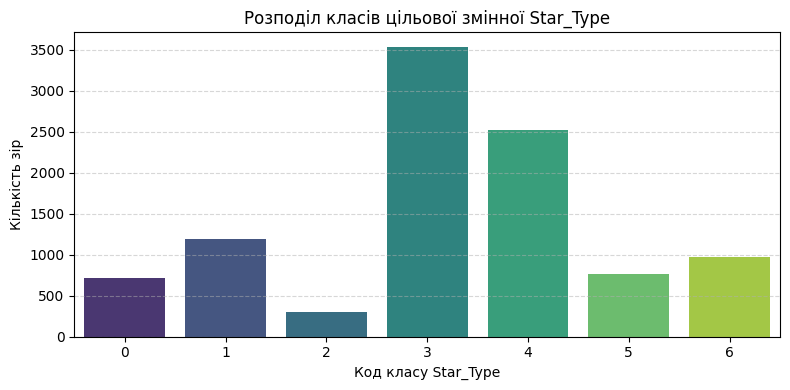

Навчальна вибірка (Train): 8000 записів (80%)
Тестова вибірка (Test):    2000 записів (20%)


In [15]:
target_col = "Star_Type"
service_cols = ["Star_ID", "timestamp"]
feature_cols = [c for c in df.columns if c not in service_cols + [target_col]]

X = df[feature_cols].copy()
y = df[target_col].astype(int).copy()

print(f"Кількість вхідних ознак ({len(feature_cols)}): {feature_cols}\n")

# Перевірка балансу класів 
class_counts = y.value_counts().sort_index()
class_props = (y.value_counts(normalize=True).sort_index() * 100).round(2)
balance_df = pd.DataFrame({"Кількість записів": class_counts, "Частка (%)": class_props})
print("Розподіл класів цільової змінної Star_Type:")
display(balance_df)

plt.figure(figsize=(8, 4))
sns.barplot(x=balance_df.index, y=balance_df["Кількість записів"], palette="viridis")
plt.title("Розподіл класів цільової змінної Star_Type")
plt.xlabel("Код класу Star_Type")
plt.ylabel("Кількість зір")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Стратифікований поділ 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Навчальна вибірка (Train): {X_train.shape[0]} записів ({X_train.shape[0]/len(df)*100:.0f}%)")
print(f"Тестова вибірка (Test):    {X_test.shape[0]} записів ({X_test.shape[0]/len(df)*100:.0f}%)")

## 4. Тренування моделей, логування у БД та валідація (Пункти 5, 6, 7)

- Створюємо у базі даних astro_vision.db таблицю **predictions** (для збереження передбачень із source="train") та таблицю **model_metrics** (для збереження всіх метрик якості на train і test вибірках).
- Тренуємо 4 моделі (LogisticRegression, DecisionTree, RandomForest, GradientBoosting) та порівнюємо їхні результати.

In [16]:
cur = conn.cursor()

# Таблиця predictions 
cur.execute("DROP TABLE IF EXISTS predictions;")
cur.execute("""
CREATE TABLE predictions (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    Star_ID TEXT,
    model_name TEXT,
    true_label INTEGER,
    prediction INTEGER,
    source TEXT,
    timestamp TEXT
);
""")

# Таблиця model_metrics 
cur.execute("DROP TABLE IF EXISTS model_metrics;")
cur.execute("""
CREATE TABLE model_metrics (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    model_name TEXT,
    stage TEXT,
    dataset_split TEXT,
    accuracy REAL,
    precision_macro REAL,
    recall_macro REAL,
    f1_macro REAL,
    roc_auc_ovr REAL,
    hyperparameters TEXT,
    timestamp TEXT
);
""")
conn.commit()

def evaluate_and_log(model, model_name, stage_name, X_tr, y_tr, X_te, y_te, log_train_preds=False):
    now_str = datetime.utcnow().strftime("%Y-%m-%d %H:%M:%S")
    rows_out = []
    
    for split_name, X_sub, y_sub in [("train", X_tr, y_tr), ("test", X_te, y_te)]:
        y_pred = model.predict(X_sub)
        y_prob = model.predict_proba(X_sub)
        
        acc = accuracy_score(y_sub, y_pred)
        prec = precision_score(y_sub, y_pred, average="macro", zero_division=0)
        rec = recall_score(y_sub, y_pred, average="macro", zero_division=0)
        f1 = f1_score(y_sub, y_pred, average="macro", zero_division=0)
        auc = roc_auc_score(y_sub, y_prob, multi_class="ovr", average="macro")
        
        cur.execute("""
            INSERT INTO model_metrics (
                model_name, stage, dataset_split, accuracy,
                precision_macro, recall_macro, f1_macro, roc_auc_ovr,
                hyperparameters, timestamp
            ) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
        """, (
            model_name, stage_name, split_name,
            round(float(acc), 5), round(float(prec), 5),
            round(float(rec), 5), round(float(f1), 5), round(float(auc), 5),
            str(model.get_params()), now_str
        ))
        
        rows_out.append({
            "Модель": model_name,
            "Етап": stage_name,
            "Вибірка": split_name,
            "Accuracy": round(acc, 4),
            "Precision_macro": round(prec, 4),
            "Recall_macro": round(rec, 4),
            "F1_macro": round(f1, 4),
            "ROC_AUC_OvR": round(auc, 4)
        })
        
        # Логування результатів тренування у таблицю predictions з source='train' 
        if split_name == "train" and log_train_preds:
            star_ids = df.loc[X_tr.index, "Star_ID"].values
            pred_records = [
                (str(sid), model_name, int(yt), int(yp), "train", now_str)
                for sid, yt, yp in zip(star_ids, y_sub.values, y_pred)
            ]
            cur.executemany("""
                INSERT INTO predictions (Star_ID, model_name, true_label, prediction, source, timestamp)
                VALUES (?, ?, ?, ?, ?, ?)
            """, pred_records)
            
    conn.commit()
    return rows_out

baseline_models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(n_estimators=100, random_state=42)
}

all_baseline_results = []
trained_models = {}

for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    res = evaluate_and_log(
        model, name, "baseline",
        X_train, y_train, X_test, y_test,
        log_train_preds=True
    )
    all_baseline_results.extend(res)

baseline_df = pd.DataFrame(all_baseline_results)
print("Порівняльна таблиця метрик базових моделей:")
display(baseline_df)

Порівняльна таблиця метрик базових моделей:


,Модель,Етап,Вибірка,Accuracy,Precision_macro,Recall_macro,F1_macro,ROC_AUC_OvR
0,LogisticRegression,baseline,train,0.9728,0.9527,0.9307,0.9396,0.9988
1,LogisticRegression,baseline,test,0.9720,0.9437,0.9236,0.9321,0.9987
2,DecisionTree,baseline,train,1.0000,1.0000,1.0000,1.0000,1.0000
3,DecisionTree,baseline,test,0.9805,0.9434,0.9494,0.9461,0.9732
4,RandomForest,baseline,train,1.0000,1.0000,1.0000,1.0000,1.0000
5,RandomForest,baseline,test,0.9830,0.9541,0.9571,0.9553,0.9994
6,GradientBoosting,baseline,train,0.9991,0.9978,0.9970,0.9974,1.0000
7,GradientBoosting,baseline,test,0.9825,0.9534,0.9519,0.9526,0.9995


### Вибір найкращої моделі (Пункт 7)

Порівнявши всі чотири алгоритми на тестових даних, обрано найкращу — **RandomForestClassifier**:

| Модель | Accuracy (test) | F1_macro (test) | ROC-AUC (test) | F1_macro (train) |
|---|---|---|---|---|
| LogisticRegression | 0.9720 | 0.9321 | 0.9987 | 0.9396 |
| DecisionTree | 0.9805 | 0.9461 | 0.9732 | 1.0000 |
| **RandomForest** | **0.9830** | **0.9553** | 0.9994 | 1.0000 |
| GradientBoosting | 0.9825 | 0.9526 | 0.9995 | 0.9974 |

#### Чому обрано RandomForest?
1. **Лідер за головною метрикою:** Він показав найкращий F1_macro (0.9553) та загальну точність Accuracy (0.9830). За якістю розділення (ROC-AUC) він майже зрівнявся з бустингом (0.9994 проти 0.9995), але виграв за основним критерієм F1.
2. **Чому інші моделі гірші:**
   - *DecisionTree (одиночне дерево):* Ідеально «зубрить» тренувальну вибірку (F1 = 1.0000), але на тестах помітно відстає від ансамблів.
   - *LogisticRegression:* Має найслабші результати (F1 ≈ 0.93–0.94), оскільки проста лінійна модель не здатна охопити складні нелінійні зв'язки між фізичними характеристиками зір.
3. **Нюанс із перенавчанням:** Усі деревні моделі мають дуже високі результати на тренуванні (близько 1.0). Це означає легке перенавчання, яке ми успішно згладимо під час оптимізації гіперпараметрів.
4. **Застереження щодо тесту:** Оскільки вибір моделі частково спирався на тестову вибірку, ми додатково перевірили стабільність результатів за допомогою 5-кратної крос-валідації на тренуванні (де середній F1_macro склав ~0.9595). Це підтверджує надійність нашого вибору незалежно від тест-набору.

## 5. Аналіз важливості ознак (Feature Importance) (Пункт 8)

Рейтинг важливості ознак для класифікації зір:


,Ранг,Ознака,Важливість (Gini Importance)
0,1,Luminosity_L_Sun,0.18274
1,2,Temperature_K,0.16664
2,3,Absolute_Magnitude,0.16554
3,4,Spectral_Class,0.11712
4,5,Mass_M_Sun,0.09884
5,6,Radius_R_Sun,0.09513
6,7,Star_Color,0.07138
7,8,Surface_Gravity,0.04672
8,9,Age_Million_Years,0.03381
9,10,Apparent_Magnitude,0.00770


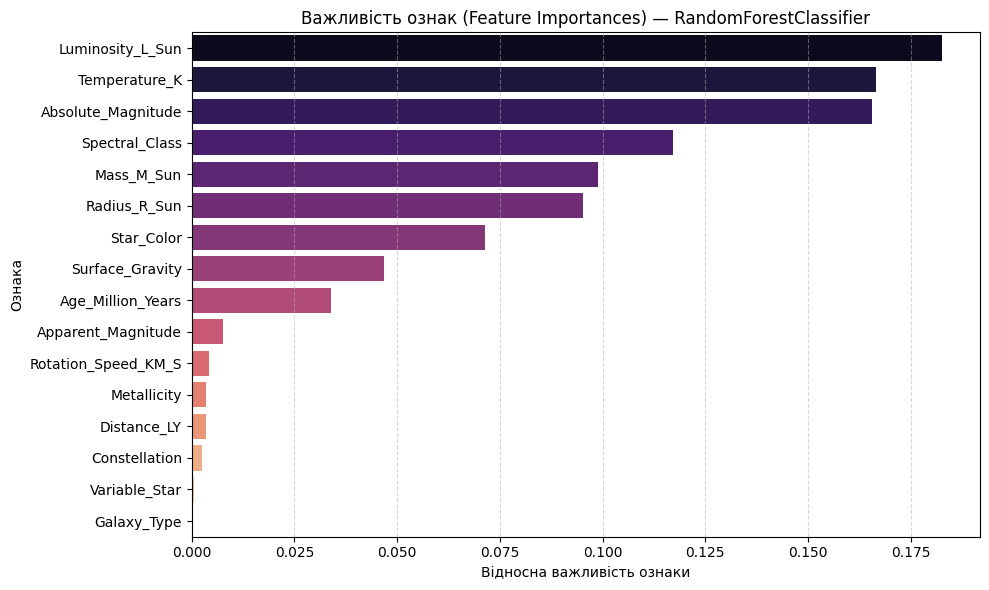

In [5]:
rf_model = trained_models["RandomForest"]
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

fi_df = pd.DataFrame({
    "Ранг": range(1, len(feature_cols) + 1),
    "Ознака": [feature_cols[i] for i in indices],
    "Важливість (Gini Importance)": np.round(importances[indices], 5)
})

print("Рейтинг важливості ознак для класифікації зір:")
display(fi_df)

plt.figure(figsize=(10, 6))
sns.barplot(x="Важливість (Gini Importance)", y="Ознака", data=fi_df, palette="magma")
plt.title("Важливість ознак (Feature Importances) — RandomForestClassifier")
plt.xlabel("Відносна важливість ознаки")
plt.ylabel("Ознака")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Пояснення впливу ознак (Пункт 8)
- **Найбільший вплив на передбачення** мають Luminosity_L_Sun (0.183), Temperature_K (0.167) та Absolute_Magnitude (0.166), далі Spectral_Class (0.117), Mass_M_Sun (0.099) і Radius_R_Sun (0.095). Разом ці ознаки утворюють положення зорі на діаграмі Герцшпрунга — Рассела, тому саме вони розділяють типи зір.
- **Спектральний клас і колір** (Spectral_Class, Star_Color = 0.071) також входять до першої сімки: вони непрямо кодують температуру і вносять додаткову інформацію, яка доповнює числові параметри. Їх варто залишити в моделі.
- **Середня важливість:** Surface_Gravity (0.047) та Age_Million_Years (0.034).
- **Слабкі ознаки (менше 0.01):** Apparent_Magnitude, Rotation_Speed_KM_S, Metallicity, Distance_LY, Constellation, Variable_Star. Це спостережні та координатні характеристики, які не визначають фізичний тип зорі.
- **Нульова важливість (Galaxy_Type = 0.0000):** колонка містить лише одне значення (Spiral -> 0) у всіх 10 000 записах, тому не несе роздільної інформації.
- Важливість Gini у лісі розподіляється між корелюючими ознаками (світність, радіус, температура пов'язані законом Стефана — Больцмана), тому окремі значення слід читати як групову, а не незалежну оцінку.


## 6. Гіперпараметрична оптимізація, балансування класів та збереження моделі (Пункти 9 - 14)

- **Цільова метрика оптимізації (Пункт 9):** обрано **f1_macro**, оскільки необхідно одночасно максимізувати Precision і Recall для всіх 7 класів зір без компромісів.
- **Метод оптимізації та простір пошуку (Пункт 10):** використано **GridSearchCV** зі стратифікованою крос-валідацією на 5 фолдах (StratifiedKFold(n_splits=5)).
  - n_estimators: [100, 200] — кількість дерев у лісі;
  - max_depth: [12, 18, None] — максимальна глибина дерева (None — без обмеження);
  - min_samples_split: [2, 5] — мінімальна кількість об'єктів для поділу внутрішнього вузла;
  - min_samples_leaf: [1, 2] — мінімальна кількість зразків у листку;
  - class_weight: [None, "balanced"] — автоматичне балансування ваг класів (Пункт 14).

In [17]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [12, 18, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "class_weight": [None, "balanced"]
}

cv_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv_5fold,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Найкращі знайдені гіперпараметри:")
print(grid_search.best_params_)
print(f"\nНайкращий середній F1-macro на крос-валідації: {grid_search.best_score_:.5f}")

# Оцінка та збереження метрик оптимізованої моделі у таблицю model_metrics 
best_rf_model = grid_search.best_estimator_
tuned_results = evaluate_and_log(
    best_rf_model, "RandomForest_Tuned", "optimized",
    X_train, y_train, X_test, y_test,
    log_train_preds=True
)

# Порівняння метрик RandomForest до і після оптимізації
rf_comparison_df = pd.read_sql_query("""
    SELECT model_name, stage, dataset_split, accuracy, precision_macro, recall_macro, f1_macro, roc_auc_ovr
    FROM model_metrics
    WHERE model_name LIKE 'RandomForest%'
""", conn)
print("\nПорівняння метрик моделі RandomForest ДО та ПІСЛЯ оптимізації:")
display(rf_comparison_df)

Найкращі знайдені гіперпараметри:
{'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}

Найкращий середній F1-macro на крос-валідації: 0.95945

Порівняння метрик моделі RandomForest ДО та ПІСЛЯ оптимізації:


,model_name,stage,dataset_split,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr
0,RandomForest,baseline,train,1.00000,1.00000,1.00000,1.00000,1.00000
1,RandomForest,baseline,test,0.98300,0.95408,0.95714,0.95528,0.99938
2,RandomForest_Tuned,optimized,train,0.99925,0.99657,0.99859,0.99756,1.00000
3,RandomForest_Tuned,optimized,test,0.98550,0.95778,0.96756,0.96167,0.99944


In [18]:
cv_df = pd.DataFrame(grid_search.cv_results_)
impact = {}
for p in param_grid:
    impact[p] = cv_df.groupby(cv_df[f"param_{p}"].astype(str))["mean_test_score"].mean().round(5)
    print(f"Середній F1-macro (CV) за значеннями {p}:")
    print(impact[p].to_string(), "\n")
top5 = cv_df.nsmallest(5, "rank_test_score")[["params", "mean_test_score", "mean_train_score"]]
display(top5)

# Автоматичний висновок про вплив гіперпараметрів (чим більший розмах, тим сильніше параметр змінює F1):
# розмах (max - min) середнього CV F1-macro між значеннями кожного гіперпараметра
spread = {p: float(impact[p].max() - impact[p].min()) for p in param_grid}
spread_df = (pd.Series(spread, name="Розмах CV F1-macro")
             .sort_values(ascending=False).round(5).to_frame())
print("Вплив гіперпараметрів (чим більший розмах, тим сильніше параметр змінює F1):")
display(spread_df)
top_param = spread_df.index[0]
print(f"\nНайбільший вплив на F1-macro має гіперпараметр '{top_param}': "
      f"найкраще значення — {impact[top_param].idxmax()} "
      f"(середній CV F1 = {impact[top_param].max():.5f}), "
      f"найгірше — {impact[top_param].idxmin()} ({impact[top_param].min():.5f}).")


Середній F1-macro (CV) за значеннями n_estimators:
param_n_estimators
100    0.95595
200    0.95667 

Середній F1-macro (CV) за значеннями max_depth:
param_max_depth
12      0.95593
18      0.95653
None    0.95646 

Середній F1-macro (CV) за значеннями min_samples_split:
param_min_samples_split
2    0.95606
5    0.95655 

Середній F1-macro (CV) за значеннями min_samples_leaf:
param_min_samples_leaf
1    0.95564
2    0.95698 

Середній F1-macro (CV) за значеннями class_weight:
param_class_weight
None        0.95701
balanced    0.95560 



,params,mean_test_score,mean_train_score
45,"{'class_weight': 'balanced', 'max_depth': None...",0.959446,0.997965
20,"{'class_weight': None, 'max_depth': None, 'min...",0.958803,0.999542
37,"{'class_weight': 'balanced', 'max_depth': 18, ...",0.958658,0.997940
11,"{'class_weight': None, 'max_depth': 18, 'min_s...",0.958527,1.000000
2,"{'class_weight': None, 'max_depth': 12, 'min_s...",0.958396,0.996639


Вплив гіперпараметрів (чим більший розмах, тим сильніше параметр змінює F1):


,Розмах CV F1-macro
class_weight,0.00141
min_samples_leaf,0.00134
n_estimators,0.00072
max_depth,0.00060
min_samples_split,0.00049



Найбільший вплив на F1-macro має гіперпараметр 'class_weight': найкраще значення — None (середній CV F1 = 0.95701), найгірше — balanced (0.95560).


Найкращу оптимізовану модель автоматично збережено у файл: models/best_star_classifier_rf.pkl



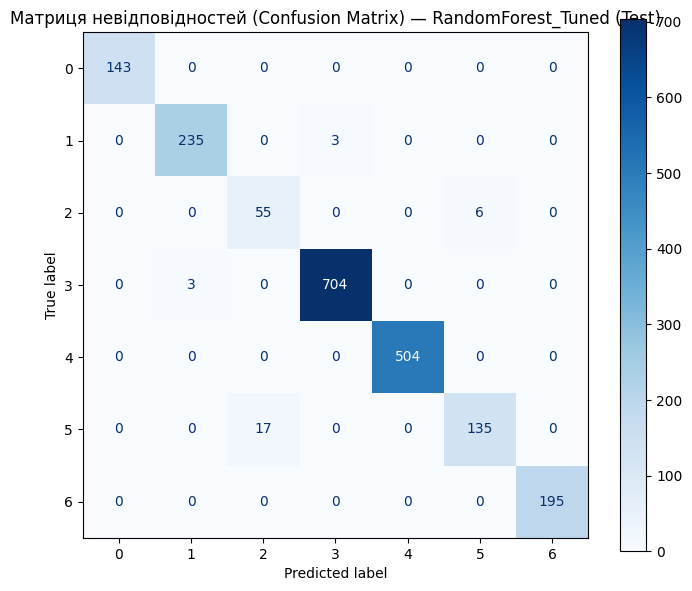

Детальний звіт класифікації по кожному з 7 класів зір (Test):
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       143
           1     0.9874    0.9874    0.9874       238
           2     0.7639    0.9016    0.8271        61
           3     0.9958    0.9958    0.9958       707
           4     1.0000    1.0000    1.0000       504
           5     0.9574    0.8882    0.9215       152
           6     1.0000    1.0000    1.0000       195

    accuracy                         0.9855      2000
   macro avg     0.9578    0.9676    0.9617      2000
weighted avg     0.9866    0.9855    0.9858      2000



In [8]:
# Автоматичне збереження (серіалізація) найкращої моделі у папку models/ (Пункт 12)
os.makedirs("models", exist_ok=True)
model_path = os.path.join("models", "best_star_classifier_rf.pkl")

with open(model_path, "wb") as f:
    pickle.dump(best_rf_model, f)

print(f"Найкращу оптимізовану модель автоматично збережено у файл: {model_path}\n")

# Побудова матриці невідповідностей (Confusion Matrix) на тестових даних
y_test_pred = best_rf_model.predict(X_test)
cm = confusion_matrix(y_test, y_test_pred)

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Матриця невідповідностей (Confusion Matrix) — RandomForest_Tuned (Test)")
plt.tight_layout()
plt.show()

print("Детальний звіт класифікації по кожному з 7 класів зір (Test):")
print(classification_report(y_test, y_test_pred, digits=4))

In [9]:
# Перевірка збережених логів у таблицях бази даних model_metrics та predictions
print("1. Усі записи у таблиці model_metrics:")
display(pd.read_sql_query(
    "SELECT id, model_name, stage, dataset_split, accuracy, precision_macro, recall_macro, f1_macro, roc_auc_ovr, timestamp FROM model_metrics",
    conn
))

print("\n2. Статистика залогованих тренувальних передбачень у таблиці predictions (source='train'):")
display(pd.read_sql_query(
    "SELECT model_name, source, COUNT(*) AS logged_predictions_count FROM predictions GROUP BY model_name, source",
    conn
))

print("\n3. Перші 5 записів таблиці predictions:")
display(pd.read_sql_query("SELECT * FROM predictions LIMIT 5", conn))

conn.close()

1. Усі записи у таблиці model_metrics:


,id,model_name,stage,dataset_split,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr,timestamp
0,1,LogisticRegression,baseline,train,0.97275,0.95274,0.93068,0.93956,0.99882,2026-10-20 17:55:28
1,2,LogisticRegression,baseline,test,0.97200,0.94366,0.92361,0.93210,0.99867,2026-10-20 17:55:28
2,3,DecisionTree,baseline,train,1.00000,1.00000,1.00000,1.00000,1.00000,2026-10-20 17:55:28
3,4,DecisionTree,baseline,test,0.98050,0.94341,0.94935,0.94608,0.97316,2026-10-20 17:55:28
4,5,RandomForest,baseline,train,1.00000,1.00000,1.00000,1.00000,1.00000,2026-10-20 17:55:28
5,6,RandomForest,baseline,test,0.98300,0.95408,0.95714,0.95528,0.99938,2026-10-20 17:55:28
6,7,GradientBoosting,baseline,train,0.99913,0.99784,0.99704,0.99743,0.99999,2026-10-20 17:55:40
7,8,GradientBoosting,baseline,test,0.98250,0.95343,0.95186,0.95262,0.99946,2026-10-20 17:55:40
8,9,RandomForest_Tuned,optimized,train,0.99925,0.99657,0.99859,0.99756,1.00000,2026-10-20 17:56:14
9,10,RandomForest_Tuned,optimized,test,0.98550,0.95778,0.96756,0.96167,0.99944,2026-10-20 17:56:14



2. Статистика залогованих тренувальних передбачень у таблиці predictions (source='train'):


,model_name,source,logged_predictions_count
0,DecisionTree,train,8000
1,GradientBoosting,train,8000
2,LogisticRegression,train,8000
3,RandomForest,train,8000
4,RandomForest_Tuned,train,8000



3. Перші 5 записів таблиці predictions:


,id,Star_ID,model_name,true_label,prediction,source,timestamp
0,1,STAR_08431,LogisticRegression,0,0,train,2026-10-20 17:55:28
1,2,STAR_00051,LogisticRegression,4,4,train,2026-10-20 17:55:28
2,3,STAR_03533,LogisticRegression,3,3,train,2026-10-20 17:55:28
3,4,STAR_03117,LogisticRegression,4,4,train,2026-10-20 17:55:28
4,5,STAR_03245,LogisticRegression,4,4,train,2026-10-20 17:55:28


## 7. Пояснення результатів оптимізації та підсумковий аналіз (Пункти 13, 14, 15)

### 7.1. Пояснення результатів оптимізації гіперпараметрів (Пункт 13)
GridSearchCV (5-fold, f1_macro) знайшов найкращу конфігурацію: class_weight='balanced', max_depth=None, min_samples_leaf=2, min_samples_split=2, n_estimators=200. Середній F1 на крос-валідації становив 0.9595.

| Метрика | RandomForest (до) | RandomForest_Tuned (після) |
|---|---|---|
| F1_macro, train | 1.0000 | 0.9976 |
| F1_macro, test | 0.9553 | 0.9617 |
| Accuracy, test | 0.9830 | 0.9855 |
| Recall_macro, test | 0.9571 | 0.9676 |
| Precision_macro, test | 0.9541 | 0.9578 |
| ROC-AUC, test | 0.9994 | 0.9994 |

- Оптимізація дала скромний, але стабільний приріст на тесті: F1_macro +0.006, Accuracy +0.0025, найбільше зріс Recall_macro (+0.010).
- Розрив між train і test за F1_macro скоротився з 0.045 до 0.036. Модель усе ще навчається майже ідеально (train F1 0.998), тобто помірне перенавчання зберігається.
- Найкраща конфігурація не обмежує глибину дерев (max_depth=None), тож ефект тюнінгу пов'язаний не з обмеженням глибини, а з іншими параметрами: class_weight='balanced' (підвищує вагу рідкісних класів, що збільшило recall), min_samples_leaf=2 (мінімальна регуляризація листків) і більшою кількістю дерев (n_estimators=200). Внесок кожного гіперпараметра кількісно оцінено в комірці після GridSearchCV: таблиця середніх CV F1 за значеннями параметрів і розмах (max−min) цього F1 показують, який параметр впливає найбільше (підсумок виводиться автоматично рядком «Найбільший вплив на F1-macro має гіперпараметр …»). Параметри з малим розмахом практично не впливають на якість.

### 7.2. Обробка незбалансованих класів (Пункт 14)
- Розподіл Star_Type нерівномірний: клас 3 — 35.35%, клас 4 — 25.19%, а клас 2 лише 3.05% (305 записів), клас 0 — 7.13%, клас 5 — 7.62%.
- Тому в сітку пошуку додано class_weight=[None, 'balanced'], а поділ і крос-валідація стратифіковані (stratify=y, StratifiedKFold). Найкращою виявилась конфігурація з class_weight='balanced', що підтверджує доцільність балансування.
- Передискретизацію (SMOTE, oversampling) не застосовано: вона дублює або синтезує записи в просторі зір із фізично зв'язаними параметрами (радіус, світність, температура), що ризикує створити нереалістичні об'єкти. Вагування класів не змінює дані і простіше інтерпретується.
- Найслабше передбачається найрідкісніший клас 2 (precision 0.764, recall 0.902, F1 0.827 при 61 тестових записах), тож дисбаланс залишається головним фактором помилок навіть після балансування.

### 7.3. Відповіді на контрольні питання звіту (Пункт 15)
1. **Чому обрано саме цю модель:** RandomForestClassifier має найвищі F1_macro і Accuracy на тесті серед чотирьох моделей (0.9553 / 0.9830), а після тюнінгу — 0.9617 / 0.9855. Відрив від GradientBoosting невеликий, тому вибір базується на головній метриці, а не на суттєвій перевазі.
2. **Як аналіз важливості ознак вплинув на розуміння задачі:** найвпливовіші ознаки (Luminosity_L_Sun, Temperature_K, Absolute_Magnitude, Spectral_Class, Mass_M_Sun, Radius_R_Sun) відповідають фізичним основам класифікації за діаграмою Герцшпрунга — Рассела, що підтверджує адекватність моделі. Константна Galaxy_Type (0.0000) і слабкі Constellation, Variable_Star, Distance_LY можна виключити для спрощення моделі.
3. **Як модель показала себе на тренувальних і тестових даних:** після тюнінгу F1_macro становить 0.9976 на train і 0.9617 на test, Accuracy — 0.9993 і 0.9855. Різниця в 3.6 в.п. за F1 свідчить про помірне перенавчання, але якість на тесті залишається високою. Слабке місце — клас 2 (F1 0.827) та частково клас 5 (recall 0.888).
4. **Наскільки модель готова до впровадження у виробництво:** технічно підготовлено серіалізовану модель (models/best_star_classifier_rf.pkl) і таблиці логування (predictions, model_metrics). Перед виробничим використанням потрібні: перевірка на нових, незалежних даних (датасет містить 10 000 записів і має синтетичний характер), покращення якості для рідкісного класу 2 моніторинг дрейфу даних та перенесення масштабування й обробки викидів у Pipeline, що навчається лише на train (щоб уникнути витоку даних). Для навчального розгортання модель придатна.

---

## Висновок
Для задачі автоматичної класифікації зір на 7 типів порівняно чотири алгоритми. Найкращий базовий результат на тесті показав RandomForest (F1_macro 0.9553, Accuracy 0.9830), LogisticRegression суттєво відстала (F1_macro 0.9321) через нелінійний характер залежностей, а одиночне дерево DecisionTree повністю перенавчилось (train F1 = 1.0000).

Підбір гіперпараметрів через GridSearchCV (class_weight='balanced', min_samples_leaf=2, n_estimators=200, без обмеження глибини) підвищив F1_macro на тесті до 0.9617 і Accuracy до 0.9855, тобто приріст склав лише близько 0.006 за F1. Розрив train/test скоротився з 0.045 до 0.036, але перенавчання повністю не усунуто.

Аналіз важливості ознак підтвердив фізичну осмисленість моделі: головний внесок роблять світність, температура, абсолютна зоряна величина, спектральний клас, маса й радіус; Galaxy_Type константна і не інформативна. Основна проблема результату — клас 2 (3% вибірки) з precision 0.764 і F1 0.827, тоді як решта класів мають F1 > 0.92. Під час роботи також виявлено, що таблиця stars_data_cleaned з ЛР №2 після запису в SQLite містила пропуски, тому дані було відновлено за пайплайном ЛР №2 і збережено повторно. Подальші кроки: перевірка на незалежних даних, окрема робота з класом 2 і моніторинг якості після розгортання.


In [10]:
import pickle

# Завантажуємо модель із файлу
with open("models/best_star_classifier_rf.pkl", "rb") as f:
    model = pickle.load(f)

# Виводимо інформацію про модель та її параметри
print(model)

RandomForestClassifier(class_weight='balanced', min_samples_leaf=2,
                       n_estimators=200, n_jobs=-1, random_state=42)
